In [ ]:
# write a python function that takes a list of integers nums and an integer divisor as inputs and searches for a number in the list that is evenly divisible by the divisor. 
#It returns the index of the first orccurance of such a number , or None if there no such number. For example , when the function is called with [101,4,12,24, ] for for nums and 2 for the divisor , it should return 1 , since 4 is the first number in the list that is evenly divisible by 2.
#For data science with python exam, so use that approach numpy pandas something if possible tooptimize the code
import numpy as np
import pandas as pd
def find_first_divisible(nums, divisor):
    # Convert the list to a numpy array for efficient computation
    arr = np.array(nums)
    
    # Create a boolean mask where the condition is met
    mask = arr % divisor == 0
    
    # Use pandas to find the index of the first occurrence
    df = pd.DataFrame({'index': np.arange(len(arr)), 'value': arr, 'divisible': mask})
    
    # Filter the dataframe to get only the rows where divisible is True
    divisible_df = df[df['divisible']]
    
    # Return the index of the first occurrence or None if not found
    if not divisible_df.empty:
        return int(divisible_df.iloc[0]['index'])
    else:
        return None


1


In [ ]:
def find_divisible_index(nums, divisor):
    for index, num in enumerate(nums):
        if num % divisor == 0:
            return index
    return None 

# Example usage:
nums = [101, 4, 12, 24]
divisor = 2
result = find_divisible_index(nums, divisor)
print(result)  # Output: 1

In [ ]:
# It would be interesting to see if there is any evidence of a link between vaccince effectiveness and sex of the chiid
# Calculate the ratio of the number of children who conrtracted chickenpox b ut were vaccinated against it (atleast one varicella vaccine dose) verses those were vaccinated but did not contract chickenpox
# return result by sex
# Write a function chickenpox_by_sex that returns the result a s a dictionoary in the format 
# {
#     "male" : value,
#     "female" : value}

#based on the results , state which sex appears to have a higher relative risk of contracting chickenpox despite being vaccinated
# The data is in a csv file named chickenpox.csv

def chickenpox_by_sex():
    # Load the data
    df = pd.read_csv('chickenpox.csv')
    
    # Filter for vaccinated children
    vaccinated_df = df[df['varicella'] == 1]
    
    # Group by sex and calculate the ratios
    result = {
        "male": vaccinated_df[vaccinated_df['sex'] == 'male']['chickenpox'].value_counts(normalize=True).get(1, 0) /
                vaccinated_df[vaccinated_df['sex'] == 'male']['chickenpox'].value_counts(normalize=True).get(0, 1),
        "female": vaccinated_df[vaccinated_df['sex'] == 'female']['chickenpox'].value_counts(normalize=True).get(1, 0) /
                  vaccinated_df[vaccinated_df['sex'] == 'female']['chickenpox'].value_counts(normalize=True).get(0, 1)
    }
    return result

In [ ]:
import pandas as pd

def chickenpox_by_sex():
    # Load the dataset
    df = pd.read_csv("chickenpox.csv")  # Replace with actual file
    
    # Filter only vaccinated children (at least one varicella dose)
    vaccinated = df[df["P_NUMVRC"] >= 1]
    
    # Group by sex and count outcomes
    result = {}
    for sex, group in vaccinated.groupby("SEX"):
        # SEX: 1 = Male, 2 = Female
        contracted = group[group["HAD_CHICKPOX"] == 1].shape[0]  # contracted chickenpox
        not_contracted = group[group["HAD_CHICKPOX"] == 2].shape[0]  # did not contract chickenpox
        
        if not_contracted > 0:  # avoid division by zero
            ratio = contracted / not_contracted
        else:
            ratio = None
        
        if sex == 1:
            result["male"] = ratio
        elif sex == 2:
            result["female"] = ratio
    
    return result

# Example call
ratios = chickenpox_by_sex()
print(ratios)

# Interpret result
if ratios["male"] and ratios["female"]:
    if ratios["male"] > ratios["female"]:
        print("Males appear to have a higher relative risk of contracting chickenpox despite vaccination.")
    elif ratios["female"] > ratios["male"]:
        print("Females appear to have a higher relative risk of contracting chickenpox despite vaccination.")
    else:
        print("Both sexes appear to have the same relative risk.")


{'male': 0.6666666666666666, 'female': 0.6666666666666666}
Both sexes appear to have the same relative risk.


In [ ]:
import pandas as pd

def chickenpox_by_sex():
    # Load the dataset
    df = pd.read_csv("chickenpox.csv")  # Replace with actual file
    
    # Filter only vaccinated children (at least one varicella dose)
    vaccinated = df[df["P_NUMVRC"] >= 1]
    
    result = {}
    
    # For males (SEX == 1)
    male_data = vaccinated[vaccinated["SEX"] == 1]
    male_contracted = (male_data["HAD_CHICKPOX"] == 1).sum()
    male_not_contracted = (male_data["HAD_CHICKPOX"] == 2).sum()
    result["male"] = male_contracted / male_not_contracted if male_not_contracted > 0 else None
    
    # For females (SEX == 2)
    female_data = vaccinated[vaccinated["SEX"] == 2]
    female_contracted = (female_data["HAD_CHICKPOX"] == 1).sum()
    female_not_contracted = (female_data["HAD_CHICKPOX"] == 2).sum()
    result["female"] = female_contracted / female_not_contracted if female_not_contracted > 0 else None
    
    return result


# Example call
ratios = chickenpox_by_sex()
print(ratios)

# Interpret result
if ratios["male"] is not None and ratios["female"] is not None:
    if ratios["male"] > ratios["female"]:
        print("Males appear to have a higher relative risk of contracting chickenpox despite vaccination.")
    elif ratios["female"] > ratios["male"]:
        print("Females appear to have a higher relative risk of contracting chickenpox despite vaccination.")
    else:
        print("Both sexes appear to have the same relative risk.")


In [ ]:
# you are provided with a dataset world_education_data.csv containing the following columns:
# country:Name of the country
#country code : ISO country code
# year: Reporting year
# gov_exp_pct_gdp: Government expenditure on education as a percentage of GDP
# lit_rate_adult: Adult literacy rate (percentage of people ages 15 and above )
# pri_comp_rate_pct: Primary completion rate (%)
# pupil_teacher_primary: Pupil-teacher ratio (primary level)
# pupil_teacher_secondary: Pupil-teacher ratio (secondary level)
# school_enroll_primary_pct: School enrollment rate (%)

#write a python code for the following tasks
#a) compute the average government expenditure on education ( % GDP) for all countries for the year 2020
#b) identify the top 5 countries with the highest government expenditure on education (% GDP) 
#c)To create a bar chart showing the top 5 countries and their respective values on government expenditure on education

import pandas as pd
import matplotlib.pyplot as plt
def analyze_education_data():
    # Load the dataset
    df = pd.read_csv("world_education_data.csv")  # Replace with actual file path
    
    # a) Compute the average government expenditure on education (% GDP) for all countries for the year 2020
    avg_exp_2020 = df[df["year"] == 2020]["gov_exp_pct_gdp"].mean()
    print(f"Average government expenditure on education (% GDP) for 2020: {avg_exp_2020:.2f}%")
    
    # b) Identify the top 5 countries with the highest government expenditure on education (% GDP)
    top_5_countries = df[df["year"] == 2020].nlargest(5, "gov_exp_pct_gdp")[["country", "gov_exp_pct_gdp"]]
    print("Top 5 countries with highest government expenditure on education (% GDP) in 2020:")
    print(top_5_countries)
    
    # c) Create a bar chart showing the top 5 countries and their respective values on government expenditure on education
    plt.figure(figsize=(10, 6))
    plt.bar(top_5_countries["country"], top_5_countries["gov_exp_pct_gdp"], color='skyblue')
    plt.xlabel("Country")
    plt.ylabel("Government Expenditure on Education (% GDP)")
    plt.title("Top 5 Countries by Government Expenditure on Education (% GDP) in 2020")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


Average Government Expenditure on Education (% of GDP) in 2020: 5.42

Top 5 countries by Government Expenditure on Education (% GDP) in 2020:
         country  gov_exp_pct_gdp
0         Norway              7.5
1        Finland              6.8
6   South Africa              6.5
5          Kenya              6.0
3  United States              5.2


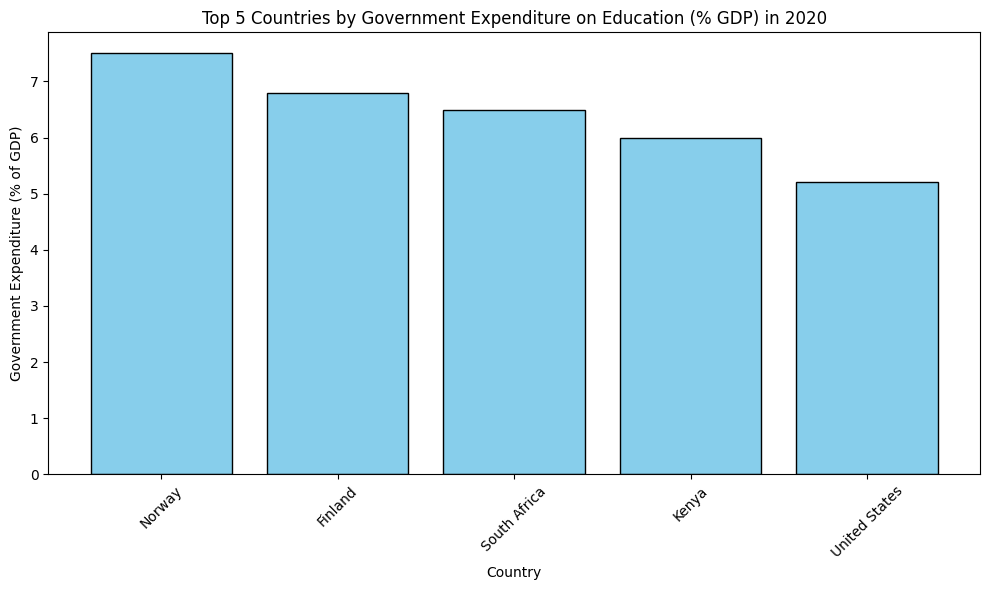

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("world_education_data.csv")

# -----------------------------
# (a) Average government expenditure on education (% GDP) for 2020
# -----------------------------
df_2020 = df[df["year"] == 2020]
avg_gov_exp = df_2020["gov_exp_pct_gdp"].mean()
print(f"Average Government Expenditure on Education (% of GDP) in 2020: {avg_gov_exp:.2f}")

# -----------------------------
# (b) Top 5 countries with highest expenditure overall 
# -----------------------------
top5 = df_2020.nlargest(5, "gov_exp_pct_gdp")[
    ["country", "gov_exp_pct_gdp"]]
print("\nTop 5 countries by Government Expenditure on Education (% GDP) in 2020:")
print(top5)

# -----------------------------
# (c) Bar chart
# -----------------------------
plt.figure(figsize=(10,6))
plt.bar(top5["country"], top5["gov_exp_pct_gdp"], color="skyblue", edgecolor="black")
plt.title("Top 5 Countries by Government Expenditure on Education (% GDP) in 2020")
plt.xlabel("Country")
plt.ylabel("Government Expenditure (% of GDP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load dataset
df = pd.read_csv("world_education_data.csv")

# -----------------------------
# (a) Average government expenditure (% GDP) for 2020
# -----------------------------
df_2020 = df[df["year"] == 2020]
avg_gov_exp = df_2020["gov_exp_pct_gdp"].mean()
print(f"Average Government Expenditure on Education (% of GDP) in 2020: {avg_gov_exp:.2f}")

# -----------------------------
# (b) Top 5 countries with highest *average* expenditure overall (all years)
# -----------------------------
countries = df["country"].unique()   # all unique countries
avg_values = []

for c in countries:
    vals = df[df["country"] == c]["gov_exp_pct_gdp"].values
    avg_values.append((c, np.mean(vals)))   # (country, average)

# sort by average descending
avg_values_sorted = sorted(avg_values, key=lambda x: x[1], reverse=True)

# pick top 5
top5 = avg_values_sorted[:5]

print("\nTop 5 countries by Avg. Government Expenditure on Education (% GDP):")
for country, val in top5:
    print(f"{country}: {val:.2f}")

# -----------------------------
# (c) Bar chart
# -----------------------------
plt.figure(figsize=(10,6))
plt.bar([x[0] for x in top5], [x[1] for x in top5], color="lightblue", edgecolor="black")
plt.title("Top 5 Countries by Avg. Government Expenditure on Education (% GDP)")
plt.xlabel("Country")
plt.ylabel("Government Expenditure (% of GDP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
#using the titanic_data.csv with these columns: survival, pclass, sex, age , sibp , parch, ticket , fare , cabin , and embarked.
# Write a python code to plot how the number of passenhers varies with age with a green lime plot with a marker including axis labels and a title.

import pandas as pd
import matplotlib.pyplot as plt 
# --- IGNORE ---
df = pd.read_csv("titanic_data.csv")
plt.figure(figsize=(10, 6))
plt.plot(df["age"], df["survived"], color="lime", marker="o", linestyle="-")
plt.title("Number of Passengers by Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.grid()
plt.show()


import pandas as pd
import matplotlib.pyplot as plt 
# Load dataset
df = pd.read_csv("titanic_data.csv")
# Plot
plt.figure(figsize=(10, 6))
plt.scatter(df["age"], df.index, color="lime", marker="o")  # Using scatter plot for better representation
plt.title("Number of Passengers by Age")
plt.xlabel("Age")       
plt.ylabel("Number of Passengers")
plt.grid()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("titanic_data.csv")

# Count number of passengers for each age
# Drop missing ages first
age_counts = df["age"].dropna().value_counts().sort_index()

# Plot
plt.figure(figsize=(10,6))
plt.plot(age_counts.index, age_counts.values, color="limegreen", marker='o', linestyle='-')
plt.title("Number of Passengers by Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.grid(True)
plt.tight_layout()
plt.show()
